# Balancing a ball on a beam with Q-learning
##### *Bonus practical: coordination between reinforcement learning agents*

#### **The beam task**
We have a beam with a ball on it. Each end of the beam can be held **low**, **middle** or **high**. If the right end is higher than the left end, the ball rolls to the left, and the other way around. On top of that there is **wind**: every step the ball gets a small random push. If the ball rolls off the beam, the episode is over. The goal is to keep the ball on the beam as long as possible (an episode lasts at most 300 steps).

The ball is a simple physics agent (it has no goals, it just rolls). The ends of the beam are controlled by **Q-learning** agents, and we can set this up in three ways:
* **one brain**: a single agent controls both ends (it has 3 x 3 = 9 actions)
* **two agents**: each end has its own agent (3 actions each), and they do not talk to each other
* **one end**: a single agent controls only the right end, the left end stays in the middle

#### **Why is this interesting?**
What makes the ball roll is only the **difference** in height between the two ends (the tilt). Left low and right middle gives the same tilt as left middle and right high. So there are many ways to do the same thing (this is called *redundancy*, or the *degrees of freedom problem*, in motor control). With two agents, each agent only controls half of the tilt. If both go up at the same time, nothing happens. So they have to find some way of dividing the work, without being told how.

#### **Q-learning (same as before)**
Every agent keeps a table Q(s, a) and after each step updates it with the TD error:

\begin{equation}
\delta = r + \gamma \max_{a'} Q(s', a') - Q(s, a), \qquad Q(s, a) \leftarrow Q(s, a) + \alpha \, \delta
\end{equation}

The reward is +0.1 for every step the ball is still on the beam, and -1 when it falls off.

#### **What does an agent see?**
The state is the position of the ball on the beam and its velocity, each cut up into 7 bins. That is 49 states. An agent does **not** see what the other end is doing (only its effect on the ball).

So remember we have the following components:
* Setup (one brain, two agents, one end)
* Wind (how strong the random pushes are)
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* Number of training steps

# Lets get started

In [2]:
import mesa
from mesa.agent import AgentSet
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import copy
from collections import deque

LEVELS = [-1, 0, 1]   # low, middle, high

# Agent setup: the ball (simple physics)

In [3]:
class Ball(mesa.Agent):
    """A ball rolling on the beam. It rolls towards the lower end and gets pushed around by the wind.
    position: -1 is the left end, +1 is the right end, beyond that it falls off
    roll_speed: how strongly the tilt accelerates the ball
    wind: standard deviation of the random push every step
    """
    def __init__(self, model, roll_speed=0.006, wind=0.008):
        super().__init__(model)
        self.roll_speed = roll_speed
        self.wind = wind
        self.reset()

    def reset(self):
        self.position = self.model.random.uniform(-0.3, 0.3)
        self.velocity = 0.0

    def step(self):
        tilt = self.model.height["right"] - self.model.height["left"]   # from -2 to +2
        self.velocity += -self.roll_speed * tilt + self.model.rng.normal(0, self.wind)
        self.position += self.velocity

    def fallen(self):
        return abs(self.position) > 1

# Agent setup: the beam controller (Q-learning)
A controller can control one end (`sides=["right"]`) or both ends (`sides=["left", "right"]`). Its actions are all combinations of levels for the ends it controls, so 3 actions for one end and 9 for two ends. The `learn()` method is exactly the same as for the herding dogs.

In [4]:
class BeamController(mesa.Agent):
    """A Q-learning agent that holds one or both ends of the beam.
    sides: which ends this agent controls
    alpha: learning rate, gamma: discount, epsilon: exploration
    """
    def __init__(self, model, sides, alpha=0.1, gamma=0.99, epsilon=0.1):
        super().__init__(model)
        self.sides = sides
        self.actions = list(itertools.product(LEVELS, repeat=len(sides)))  # e.g. (low,), (middle,), (high,)
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True
        self.Q = {}

    def observe(self):
        """The state: in which bin is the ball's position, and in which bin is its velocity?"""
        ball = self.model.ball
        position_bin = int(np.digitize(ball.position, [-0.75, -0.45, -0.15, 0.15, 0.45, 0.75]))
        velocity_bin = int(np.digitize(ball.velocity, [-0.03, -0.012, -0.004, 0.004, 0.012, 0.03]))
        return (position_bin, velocity_bin)

    def q_values(self, state):
        if state not in self.Q:
            self.Q[state] = np.zeros(len(self.actions))
        return self.Q[state]

    def act(self):
        """Pick an action (epsilon-greedy) and set the height of our end(s)."""
        self.state = self.observe()
        if self.model.random.random() < self.epsilon:
            self.action = self.model.random.randrange(len(self.actions))
        else:
            q = self.q_values(self.state)
            self.action = self.model.random.choice(np.flatnonzero(q == q.max()).tolist())
        for side, level in zip(self.sides, self.actions[self.action]):
            self.model.height[side] = level

    def learn(self, reward, done):
        """Q-learning update: compute the TD error and nudge Q(s, a)."""
        if not self.learning:
            return
        if done:
            target = reward
        else:
            target = reward + self.gamma * self.q_values(self.observe()).max()
        td_error = target - self.q_values(self.state)[self.action]
        self.q_values(self.state)[self.action] += self.alpha * td_error

# Model setup
One model step is: the controllers set the heights, the ball rolls, and the controllers learn. An episode ends when the ball falls off, or after 300 steps (then we count it as a success). The datacollector collects every step (the batch runner needs that). Next to that, the model keeps an `episode_log` with one row per episode, which we use for the learning curves.

Next to how long the ball stays on, we also keep track of the **correlation between the heights of the two ends** over the last 2000 steps. A negative correlation means the ends move in *anti-phase* (one goes up while the other goes down). A positive correlation means they move together (which partly cancels out).

In [5]:
SETUPS = {
    "one brain":  [["left", "right"]],
    "two agents": [["left"], ["right"]],
    "one end":    [["right"]],
}

class BeamModel(mesa.Model):
    def __init__(self, setup="two agents", wind=0.008, roll_speed=0.006, max_steps=300,
                 alpha=0.1, gamma=0.99, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.setup = setup
        self.max_steps = max_steps
        self.height = {"left": 0, "right": 0}
        self.ball = Ball(self, roll_speed=roll_speed, wind=wind)
        self.controllers = AgentSet(
            [BeamController(self, sides, alpha=alpha, gamma=gamma, epsilon=epsilon) for sides in SETUPS[setup]],
            random=self.random)

        self.t = 0
        self.episode = 0
        self.last_episode_length = 0
        self.recent = deque(maxlen=200)            # lengths of the last 200 episodes
        self.recent_heights = deque(maxlen=2000)   # (left, right) heights of the last 2000 steps
        self.recent_balance_time = 0
        self.recent_success_rate = 0
        self.correlation = np.nan
        self.episode_log = []                      # one row per episode, for the learning curves
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "episode": "episode",
                "recent_balance_time": "recent_balance_time",
                "recent_success_rate": "recent_success_rate",
                "height_correlation": "correlation",
            }
        )

    def height_correlation(self):
        h = np.array(self.recent_heights)
        if len(h) < 10 or h[:, 0].std() == 0 or h[:, 1].std() == 0:
            return np.nan   # e.g. in the "one end" setup the left end never moves
        return np.corrcoef(h[:, 0], h[:, 1])[0, 1]

    def new_episode(self):
        self.last_episode_length = self.t
        self.recent.append(self.t)
        self.recent_balance_time = np.mean(self.recent)
        self.recent_success_rate = np.mean([l == self.max_steps for l in self.recent])
        self.correlation = self.height_correlation()
        self.episode += 1
        self.episode_log.append({"episode": self.episode, "episode_length": self.t})
        self.t = 0
        self.ball.reset()

    def step(self):
        controllers = self.controllers
        controllers.do("act")
        self.recent_heights.append((self.height["left"], self.height["right"]))
        self.ball.step()
        self.t += 1

        done = self.ball.fallen()
        reward = -1.0 if done else 0.1   # shared reward
        controllers.do("learn", reward, done)

        if done or self.t >= self.max_steps:
            self.new_episode()
        self.datacollector.collect(self)   # every step (the batch runner needs this)

# Lets train
We train the three setups for 300,000 steps each and plot the learning curves. (This takes a minute or two.)

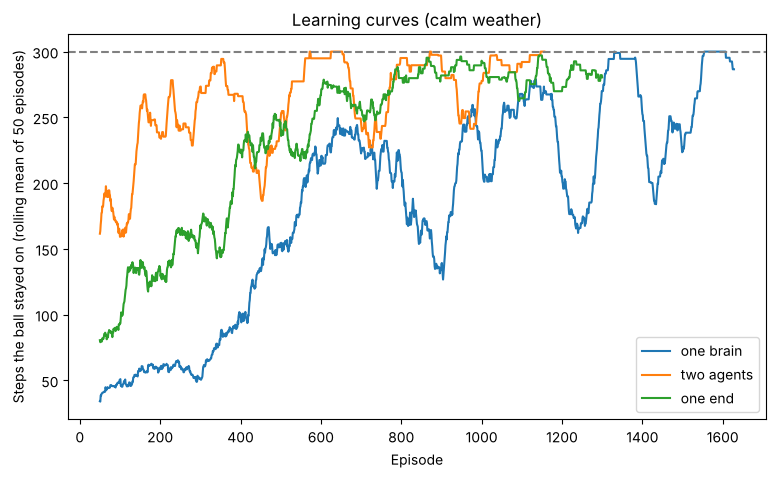

one brain    correlation between end heights: -0.13
two agents   correlation between end heights: -0.63
one end      correlation between end heights: nan


In [6]:
def train(n_steps=300_000, **params):
    model = BeamModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

trained = {setup: train(setup=setup, rng=1) for setup in SETUPS}

fig, ax = plt.subplots(figsize=(9, 5))
for setup, model in trained.items():
    df = pd.DataFrame(model.episode_log)
    ax.plot(df["episode"], df["episode_length"].rolling(50).mean(), label=setup)
ax.axhline(300, color="grey", linestyle="--")
ax.set_xlabel("Episode")
ax.set_ylabel("Steps the ball stayed on (rolling mean of 50 episodes)")
ax.set_title("Learning curves (calm weather)")
ax.legend()
plt.show()

for setup, model in trained.items():
    print(f"{setup:12s} correlation between end heights: {model.height_correlation():.2f}")

# Make a custom visualization so we can watch the beam
Again we pass a trained model, so press play and not reset. Exploration is set low.

In [7]:
@solara.component
def BeamVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()
    fig = plt.Figure(figsize=(7, 4))
    ax = fig.subplots()
    hl, hr = model.height["left"] * 0.3, model.height["right"] * 0.3   # scale the heights for drawing
    ax.plot([-1, 1], [hl, hr], color="saddlebrown", linewidth=6)        # the beam
    ax.plot([-1, -1], [-0.6, hl], color="black", linewidth=3)            # left support
    ax.plot([1, 1], [-0.6, hr], color="black", linewidth=3)              # right support
    x = model.ball.position
    y = hl + (x + 1) / 2 * (hr - hl)                                      # ball sits on the beam
    ax.scatter(x, y + 0.08, s=400, c="tab:blue", zorder=10)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-0.7, 0.7)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{model.setup}: episode {model.episode}, step {model.t}")
    solara.FigureMatplotlib(fig)

model = trained["two agents"]   # try the other setups too
for controller in model.controllers:
    controller.epsilon = 0.05

page = SolaraViz(model, components=[BeamVisualization], name="Beam balancing with Q-learning")
page

Cannot show ipywidgets in text

# Batch run: calm versus windy
Now over two seeds, for the three setups, with calm weather and with strong wind. (This takes a few minutes.)

  0%|          | 0/12 [00:00<?, ?it/s]

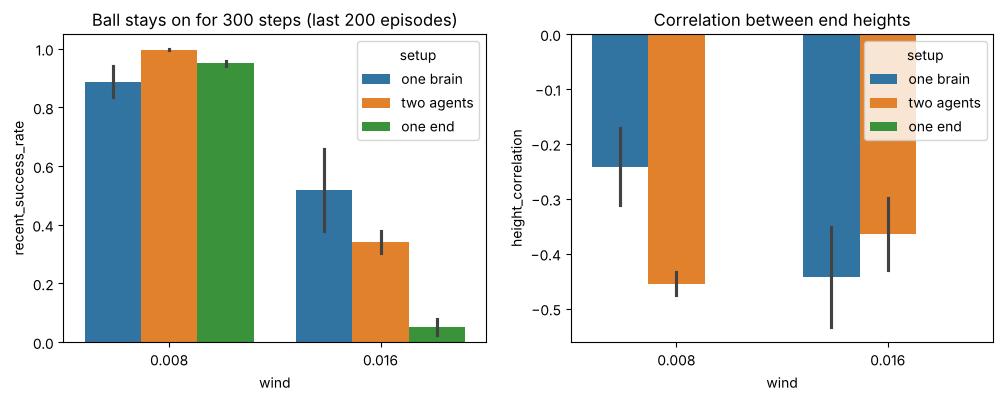

In [8]:
params = {"setup": list(SETUPS),
          "wind": [0.008, 0.016]}

results = mesa.batch_run(
    BeamModel,
    parameters=params,
    iterations=2,
    max_steps=300_000,
    number_processes=1,
    data_collection_period=-1,   # only collect at the end
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./beam_batch_run.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(results, x="wind", y="recent_success_rate", hue="setup", ax=axes[0])
sns.barplot(results, x="wind", y="height_correlation", hue="setup", ax=axes[1])
axes[0].set_title("Ball stays on for 300 steps (last 200 episodes)")
axes[1].set_title("Correlation between end heights")
plt.show()

# Partner swap
Two teams of two agents each learned to balance the ball. Did they divide the work in the same way? We take the left end of team A and the right end of team B and test them together, with learning switched off.

In [9]:
def test(model, n_episodes=200, epsilon=0.05):
    for controller in model.controllers:
        controller.learning, controller.epsilon = False, epsilon
    start = model.episode
    while model.episode < start + n_episodes:
        model.step()
    df = pd.DataFrame(model.episode_log)
    return (df[df["episode"] > start]["episode_length"] == model.max_steps).mean()

def left_and_right(model):
    controllers = list(model.controllers)
    return [c for c in controllers if c.sides == ["left"]][0], [c for c in controllers if c.sides == ["right"]][0]

team_a = trained["two agents"]
team_b = train(setup="two agents", rng=2)
print("Team A together:", test(copy.deepcopy(team_a)))
print("Team B together:", test(copy.deepcopy(team_b)))

mixed = BeamModel(setup="two agents", rng=9)
left, right = left_and_right(mixed)
left.Q = left_and_right(team_a)[0].Q
right.Q = left_and_right(team_b)[1].Q
print("Mixed team:     ", test(mixed))

Team A together: 1.0


Team B together: 1.0


Mixed team:      1.0


# Experiments for you
1. **One brain or two agents?** Which setup learns faster in calm weather? The one brain has all the information, so why could two separate agents still be faster? (Hint: count the actions.)
2. **Anti-phase.** Look at the correlation between the end heights. Did anyone tell the two agents to move in anti-phase? Where does it come from? Does the one brain do the same?
3. **Wind.** With strong wind, why does the "one end" setup fail? What does the second end add?
4. **Who does the work?** In the two agents setup, look at how often each end is low, middle or high (you can log `model.height`). Do both ends work equally hard, or does one end do most of the work?
5. **Freeze a partner.** Train two agents, then switch off learning for the left end and give the right end a fresh (empty) Q-table. Does the new right end learn faster with a stable partner than two agents learning at the same time?
6. **Partner swap.** Try other seeds. When does a mixed team work, and when not? What does that say about the division of work being a property of each agent or of the pair?
7. **Learning parameters.** What happens with $\gamma = 0$? The agent then only cares about the reward of the next step. Why is that a problem for balancing?